In [1]:
import pickle
import cv2
import pandas as pd

In [2]:
with open('data.pkl','rb') as f:
    data = pickle.load(f)

In [3]:
def save_data(data,path):
    try:
        with open(path,'wb') as f:
            pickle.dump(data,f)
    except Exception as e:
        print(e)

In [ ]:
#----- Creamos el dataframe de perros con tamaños mayores o iguales a 224
df_dog = pd.DataFrame(
    {        
    'img': [ img  for img in data['dogs'] if img.shape[0] >= 224 and  img.shape[1] >=224]
    }
)
df_dog['label'] = 'dog'

In [5]:
df_dog.info()

<class 'pandas.DataFrame'>
RangeIndex: 11044 entries, 0 to 11043
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   img     11044 non-null  object
 1   label   11044 non-null  str   
dtypes: object(1), str(1)
memory usage: 172.7+ KB


In [6]:
df_cat = pd.DataFrame({
    'img': [img for img in data['cats'] if img.shape[0] >=224 and img.shape[1] >=224 ]
})
df_cat['label'] = 'cat'

In [7]:
df_cat.info()

<class 'pandas.DataFrame'>
RangeIndex: 11017 entries, 0 to 11016
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   img     11017 non-null  object
 1   label   11017 non-null  str   
dtypes: object(1), str(1)
memory usage: 172.3+ KB


In [8]:
df = pd.concat([df_dog,df_cat],ignore_index=True)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22061 entries, 0 to 22060
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   img     22061 non-null  object
 1   label   22061 non-null  str   
dtypes: object(1), str(1)
memory usage: 344.8+ KB


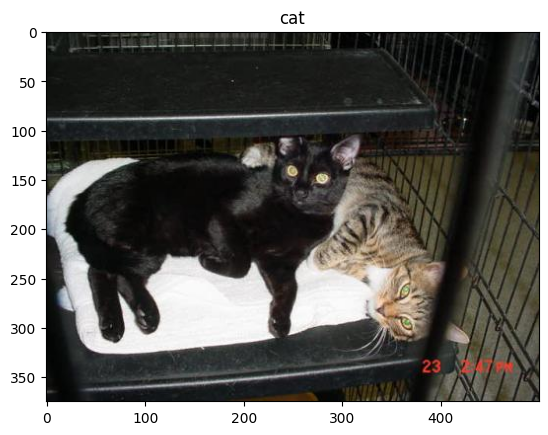

In [10]:
#-----Mostrar una imagen aleatoria
import numpy as np
import matplotlib.pyplot as plt

idx = np.random.randint(len(df))

plt.imshow(df.loc[idx, 'img'])
plt.title( df.loc[idx, 'label'])

plt.show()

In [11]:
df['img'] = df['img'].apply(lambda img: cv2.resize(img,(224,224)))

In [12]:
save_data(df,'data_resized.pkl')

In [13]:
print(df.head(1))

                                                 img label
0  [[[117, 115, 126], [121, 118, 132], [109, 106,...   dog
